# OneR vs ZeroR — vì sao chênh lệch giữa hai thuật toán lại như vậy?

Notebook này chạy lại phép so sánh OneR và ZeroR trên 8 dataset của Weka, rồi đo **một tính chất** của mỗi dataset để giải thích kết quả.

**Hai "thí sinh":**

- **ZeroR**: không nhìn cột nào, chỉ đoán nhãn đông nhất cho mọi dòng. Điểm của nó = tỉ lệ phe đông.
  - Ví dụ: `weather.nominal` có 9 `yes`, 5 `no` → đoán `yes` hết → đúng 9/14.
- **OneR**: thử từng cột, mỗi cột lập một luật ("nếu outlook = sunny thì no…"), rồi giữ lại cột đúng nhiều nhất trên dữ liệu học.

**Tính chất cần đo — "độ lời":** cột giỏi nhất của OneR đoán đúng hơn việc "cứ đoán phe đông" bao nhiêu điểm %, trên chính dữ liệu học.

**Ý tưởng chính:**

> OneR khi thi thật ≈ ZeroR + (độ lời của cột giỏi nhất) − (tiền phạt học vẹt)

Độ lời nhỏ → phần lời phần lớn là trùng hợp → ra thi thật thì mất → OneR thua ZeroR.

Cấu trúc thư mục cần có:
```
lab-data-mining/
├── datasets/        ← 8 file .arff
└── OneR_vs_ZeroR.ipynb   ← notebook này
```

## 1. Thư viện và cài đặt

In [1]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import arff
from sklearn.model_selection import StratifiedKFold

DATA_DIR = Path("datasets")   # thư mục chứa các file .arff
MIN_BUCKET = 6                # giống tham số minBucketSize mặc định của OneR trong Weka

DATASETS = ["breast-cancer", "credit-g", "diabetes", "ionosphere",
            "iris.2D", "unbalanced", "vote", "weather.nominal"]

## 2. Đọc file .arff

`scipy` đọc được file arff, nhưng cột chữ (nominal) bị trả về dạng `bytes` (ví dụ `b'sunny'`) và ô thiếu là `b'?'`. Hàm dưới đây đổi về chữ bình thường và đổi `?` thành ô trống (`NaN`).

Quy ước của Weka: **cột cuối cùng là cột nhãn (class)**.

In [2]:
def doc_arff(ten):
    data, meta = arff.loadarff(DATA_DIR / f"{ten}.arff")
    df = pd.DataFrame(data)

    loai_cot = {}      # tên cột -> 'chu' (nominal) hoặc 'so' (numeric)
    for cot in meta.names():
        kieu, gia_tri = meta[cot]
        if kieu == "nominal":
            df[cot] = df[cot].str.decode("utf-8").replace("?", np.nan)
            loai_cot[cot] = "chu"
        else:
            loai_cot[cot] = "so"

    cot_nhan = meta.names()[-1]
    thu_tu_nhan = list(meta[cot_nhan][1])   # thứ tự nhãn như khai báo trong file
    X = df.drop(columns=cot_nhan)
    y = df[cot_nhan]
    return X, y, loai_cot, thu_tu_nhan

# Thử với weather.nominal
X, y, loai_cot, thu_tu_nhan = doc_arff("weather.nominal")
X.assign(play=y)

,outlook,temperature,humidity,windy,play
0,sunny,hot,high,FALSE,no
1,sunny,hot,high,TRUE,no
2,overcast,hot,high,FALSE,yes
3,rainy,mild,high,FALSE,yes
4,rainy,cool,normal,FALSE,yes
5,rainy,cool,normal,TRUE,no
6,overcast,cool,normal,TRUE,yes
7,sunny,mild,high,FALSE,no
8,sunny,cool,normal,FALSE,yes
9,rainy,mild,normal,FALSE,yes


## 3. ZeroR — đoán phe đông

Khi hai nhãn đông bằng nhau, chọn nhãn đứng trước trong file (Weka cũng làm vậy).

In [3]:
def phe_dong(dem, thu_tu_nhan):
    # dem: Counter {nhãn: số lần}. Trả về nhãn đông nhất, hòa thì lấy nhãn đứng trước.
    return max(thu_tu_nhan, key=lambda nhan: (dem.get(nhan, 0), -thu_tu_nhan.index(nhan)))

class ZeroR:
    def fit(self, X, y, loai_cot, thu_tu_nhan):
        self.nhan = phe_dong(Counter(y), thu_tu_nhan)
        return self

    def predict(self, X):
        return np.array([self.nhan] * len(X))

ZeroR().fit(X, y, loai_cot, thu_tu_nhan).predict(X)

array(['yes', 'yes', 'yes', 'yes', 'yes', 'yes', 'yes', 'yes', 'yes',
       'yes', 'yes', 'yes', 'yes', 'yes'], dtype='<U3')

## 4. OneR — một cột, một luật

### 4a. Luật cho cột chữ (nominal)

Lập bảng đếm: mỗi giá trị của cột gặp mỗi nhãn bao nhiêu lần, rồi mỗi giá trị chọn nhãn đông nhất.

Ví dụ cột `outlook` của weather:

| outlook | no | yes | luật |
|---|---|---|---|
| sunny | 3 | 2 | → no (đúng 3) |
| overcast | 0 | 4 | → yes (đúng 4) |
| rainy | 2 | 3 | → yes (đúng 3) |

Tổng đúng = 3 + 4 + 3 = 10/14. Ô thiếu (`?`) được coi là một giá trị riêng.

In [4]:
def luat_cot_chu(x, y, thu_tu_nhan):
    x = x.fillna("?")
    bang = pd.crosstab(x, y).reindex(columns=thu_tu_nhan, fill_value=0)
    luat = {gia_tri: phe_dong(dict(dong), thu_tu_nhan) for gia_tri, dong in bang.iterrows()}
    so_dung = sum(bang.loc[gt, nhan] for gt, nhan in luat.items())
    return luat, int(so_dung), len(luat)

luat_cot_chu(X["outlook"], y, thu_tu_nhan)

({'overcast': 'yes', 'rainy': 'yes', 'sunny': 'no'}, 10, 3)

### 4b. Luật cho cột số (numeric) — cắt thành khúc

Cột số không có "giá trị" cố định để lập bảng, nên OneR **sắp xếp** rồi **cắt thành từng khúc**, mỗi khúc gán một nhãn. Cách cắt giống Weka:

1. Gom các dòng vào khúc cho tới khi có **ít nhất 6 dòng cùng một nhãn** (`MIN_BUCKET`). Không có luật này thì OneR sẽ cắt mỗi dòng thành một khúc và học thuộc lòng 100%.
2. Dòng tiếp theo vẫn cùng nhãn với phe đông của khúc → gom tiếp.
3. Dòng tiếp theo có cùng giá trị với dòng trước → gom tiếp (không được cắt giữa hai số bằng nhau).
4. Ngưỡng cắt = trung điểm giữa hai giá trị kề nhau.
5. Cuối cùng, hai khúc kề nhau cùng nhãn thì gộp lại.

Ví dụ: chiều dài cánh hoa iris → `< 2.45` là setosa, `2.45 – 4.85` là versicolor, `≥ 4.85` là virginica.

In [5]:
def luat_cot_so(x, y, thu_tu_nhan):
    co_gia_tri = x.notna()
    bang = pd.DataFrame({"x": x[co_gia_tri], "y": y[co_gia_tri]}).sort_values("x", kind="mergesort")
    xs, ys = bang["x"].to_numpy(), bang["y"].to_numpy()

    khuc = []          # mỗi khúc: [ngưỡng trên, nhãn, Counter]
    i, n = 0, len(xs)
    while i < n:
        dem = Counter()
        while True:                                        # bước 1
            dem[ys[i]] += 1
            i += 1
            if i >= n or max(dem.values()) >= MIN_BUCKET:
                break
        nhan = phe_dong(dem, thu_tu_nhan)
        while i < n and ys[i] == nhan:                     # bước 2
            dem[ys[i]] += 1
            i += 1
        while i < n and xs[i] == xs[i - 1]:                # bước 3
            dem[ys[i]] += 1
            i += 1
        nguong = (xs[i - 1] + xs[i]) / 2 if i < n else np.inf   # bước 4
        khuc.append([nguong, nhan, dem])

    gop = []                                               # bước 5
    for k in khuc:
        if gop and gop[-1][1] == k[1]:
            gop[-1][0] = k[0]
            gop[-1][2] = gop[-1][2] + k[2]
        else:
            gop.append(k)

    so_dung = sum(k[2][k[1]] for k in gop)

    y_thieu = y[~co_gia_tri]                               # dòng bị thiếu giá trị
    if len(y_thieu):
        nhan_thieu = phe_dong(Counter(y_thieu), thu_tu_nhan)
        so_dung += Counter(y_thieu)[nhan_thieu]
    else:
        nhan_thieu = phe_dong(Counter(y), thu_tu_nhan)

    luat = {"nguong": [k[0] for k in gop], "nhan": [k[1] for k in gop], "thieu": nhan_thieu}
    so_khuc = len(gop) + (1 if len(y_thieu) else 0)
    return luat, int(so_dung), so_khuc

Xi, yi, li, ti = doc_arff("iris.2D")
luat_cot_so(Xi["petallength"], yi, ti)

({'nguong': [np.float64(2.45), np.float64(4.85), inf],
  'nhan': ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'],
  'thieu': 'Iris-setosa'},
 143,
 3)

### 4c. Ghép lại thành OneR

In [6]:
class OneR:
    def fit(self, X, y, loai_cot, thu_tu_nhan):
        self.mac_dinh = phe_dong(Counter(y), thu_tu_nhan)   # dùng khi gặp giá trị lạ
        self.bang_cot = []                                   # điểm của từng cột (để xem sau)
        tot_nhat = None
        for cot in X.columns:
            if loai_cot[cot] == "chu":
                luat, so_dung, so_khuc = luat_cot_chu(X[cot], y, thu_tu_nhan)
            else:
                luat, so_dung, so_khuc = luat_cot_so(X[cot], y, thu_tu_nhan)
            self.bang_cot.append((cot, so_dung, so_khuc))
            if tot_nhat is None or so_dung > tot_nhat[2]:     # hòa thì giữ cột đứng trước
                tot_nhat = (cot, luat, so_dung, so_khuc)
        self.cot, self.luat, self.so_dung, self.so_khuc = tot_nhat
        self.loai = loai_cot[self.cot]
        return self

    def predict(self, X):
        cot = X[self.cot]
        if self.loai == "chu":
            return np.array([self.luat.get(v, self.mac_dinh) for v in cot.fillna("?")])
        nguong = np.array(self.luat["nguong"])
        ket_qua = []
        for v in cot:
            if pd.isna(v):
                ket_qua.append(self.luat["thieu"])
            else:
                ket_qua.append(self.luat["nhan"][np.searchsorted(nguong, v, side="right")])
        return np.array(ket_qua)

mo_hinh = OneR().fit(X, y, loai_cot, thu_tu_nhan)
print("Cột được chọn:", mo_hinh.cot, "| luật:", mo_hinh.luat, "| đúng:", mo_hinh.so_dung, "/", len(y))

Cột được chọn: outlook | luật: {'overcast': 'yes', 'rainy': 'yes', 'sunny': 'no'} | đúng: 10 / 14


## 5. "Thi thật" bằng 10-fold cross-validation

Chia dữ liệu thành 10 phần (giữ tỉ lệ nhãn mỗi phần giống nhau — *stratified*). Lần lượt lấy 1 phần làm đề thi, 9 phần còn lại để học.

Weka chỉ chạy 1 lần với seed = 1, nên con số hơi "may rủi". Ở đây chạy **10 lần với 10 seed khác nhau rồi lấy trung bình** cho ổn định hơn. Vì vậy số của notebook sẽ lệch Weka vài dòng, nhưng xu hướng giống hệt.

In [7]:
def cross_validation(MoHinh, X, y, loai_cot, thu_tu_nhan, so_lan=10, k=10):
    k = min(k, y.value_counts().min()) if y.value_counts().min() < k else k
    ty_le = []
    for seed in range(1, so_lan + 1):
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
        dung = 0
        for idx_hoc, idx_thi in skf.split(X, y):
            m = MoHinh().fit(X.iloc[idx_hoc], y.iloc[idx_hoc], loai_cot, thu_tu_nhan)
            dung += (m.predict(X.iloc[idx_thi]) == y.iloc[idx_thi].to_numpy()).sum()
        ty_le.append(dung / len(y))
    return float(np.mean(ty_le))

> Lưu ý: `weather.nominal` chỉ có 5 dòng `no`, mà stratified 10-fold đòi mỗi nhãn ít nhất 10 dòng. Hàm trên tự giảm số fold xuống bằng số dòng của nhãn ít nhất (5-fold cho weather). Weka vẫn chạy 10-fold được vì nó cho phép fold thiếu nhãn.

## 6. Đo tính chất của cả 8 dataset

In [8]:
dong = []
for ten in DATASETS:
    X, y, loai_cot, thu_tu_nhan = doc_arff(ten)
    N = len(y)
    so_phe_dong = Counter(y).most_common(1)[0][1]
    one = OneR().fit(X, y, loai_cot, thu_tu_nhan)

    dong.append({
        "dataset": ten,
        "so_dong": N,
        "so_cot": X.shape[1],
        "chia_nhan": dict(Counter(y)),
        "cot_gioi_nhat": one.cot,
        "so_khuc": one.so_khuc,
        "ZeroR_%": 100 * so_phe_dong / N,
        "cot_gioi_nhat_tren_du_lieu_hoc_%": 100 * one.so_dung / N,
        "do_loi_%": 100 * (one.so_dung - so_phe_dong) / N,
        "ZeroR_thi_that_%": 100 * cross_validation(ZeroR, X, y, loai_cot, thu_tu_nhan),
        "OneR_thi_that_%": 100 * cross_validation(OneR, X, y, loai_cot, thu_tu_nhan),
    })

ket_qua = pd.DataFrame(dong).set_index("dataset")
ket_qua["OneR_tru_ZeroR_%"] = ket_qua["OneR_thi_that_%"] - ket_qua["ZeroR_thi_that_%"]
ket_qua["tien_phat_hoc_vet_%"] = ket_qua["cot_gioi_nhat_tren_du_lieu_hoc_%"] - ket_qua["OneR_thi_that_%"]
ket_qua = ket_qua.sort_values("do_loi_%")
ket_qua.round(1)

,so_dong,so_cot,chia_nhan,cot_gioi_nhat,so_khuc,ZeroR_%,cot_gioi_nhat_tren_du_lieu_hoc_%,do_loi_%,ZeroR_thi_that_%,OneR_thi_that_%,OneR_tru_ZeroR_%,tien_phat_hoc_vet_%
dataset,,,,,,,,,,,,
unbalanced,856,32,"{'Active': 12, 'Inactive': 844}",WBN_GC_L_0.25,1,98.6,98.6,0.0,98.6,98.6,0.0,-0.0
breast-cancer,286,9,"{'recurrence-events': 85, 'no-recurrence-event...",inv-nodes,7,70.3,72.7,2.4,70.3,66.8,-3.5,5.9
credit-g,1000,20,"{'good': 700, 'bad': 300}",credit_amount,26,70.0,74.2,4.2,70.0,65.4,-4.6,8.8
weather.nominal,14,4,"{'no': 5, 'yes': 9}",outlook,3,64.3,71.4,7.1,64.3,48.6,-15.7,22.9
diabetes,768,8,"{'tested_positive': 268, 'tested_negative': 500}",plas,10,65.1,75.9,10.8,65.1,71.9,6.8,4.0
ionosphere,351,34,"{'g': 225, 'b': 126}",a06,7,64.1,86.9,22.8,64.1,81.9,17.8,5.0
vote,435,16,"{'republican': 168, 'democrat': 267}",physician-fee-freeze,3,61.4,95.6,34.3,61.4,95.6,34.3,0.0
iris.2D,150,2,"{'Iris-setosa': 50, 'Iris-versicolor': 50, 'Ir...",petallength,3,33.3,95.3,62.0,33.3,94.1,60.7,1.3


### So với kết quả Weka

Bảng chạy Weka trên lớp (10-fold, seed 1). Dòng `vote` đã sửa: file thật có **435 dòng**, không phải 296.

In [9]:
weka = pd.DataFrame({
    "OneR_weka": ["188/286", "661/1000", "549/768", "284/351", "138/150", "844/856", "416/435", "6/14"],
    "ZeroR_weka": ["201/286", "700/1000", "500/768", "225/351", "50/150", "844/856", "267/435", "9/14"],
}, index=DATASETS)
weka["OneR_weka_%"] = weka["OneR_weka"].map(lambda s: 100 * eval(s))
weka["ZeroR_weka_%"] = weka["ZeroR_weka"].map(lambda s: 100 * eval(s))

so_sanh = ket_qua[["ZeroR_thi_that_%", "OneR_thi_that_%"]].join(weka[["ZeroR_weka_%", "OneR_weka_%"]])
so_sanh.round(1)

,ZeroR_thi_that_%,OneR_thi_that_%,ZeroR_weka_%,OneR_weka_%
dataset,,,,
unbalanced,98.6,98.6,98.6,98.6
breast-cancer,70.3,66.8,70.3,65.7
credit-g,70.0,65.4,70.0,66.1
weather.nominal,64.3,48.6,64.3,42.9
diabetes,65.1,71.9,65.1,71.5
ionosphere,64.1,81.9,64.1,80.9
vote,61.4,95.6,61.4,95.6
iris.2D,33.3,94.1,33.3,92.0


## 7. Chart 1 — ba cột cho mỗi dataset

- **Xám**: ZeroR (đoán phe đông)
- **Xanh nhạt**: cột giỏi nhất của OneR, chấm trên chính dữ liệu đã học
- **Xanh đậm**: OneR khi thi thật

Khoảng hụt giữa xanh nhạt và xanh đậm = **tiền phạt học vẹt**.

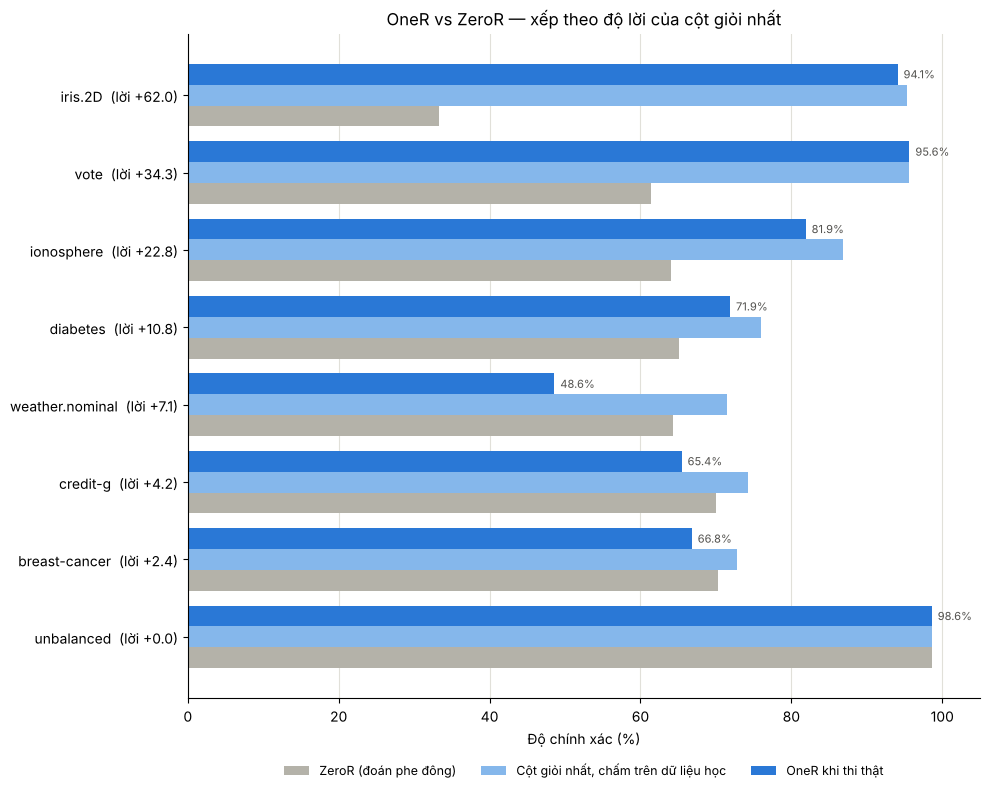

In [10]:
XAM, XANH_NHAT, XANH_DAM, DO = "#b4b2a9", "#85B7EB", "#2a78d6", "#e34948"

ten_hien = [f"{t}  (lời {v:+.1f})" for t, v in ket_qua["do_loi_%"].items()]
vi_tri = np.arange(len(ket_qua))
day = 0.27

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(vi_tri - day, ket_qua["ZeroR_%"], day, color=XAM, label="ZeroR (đoán phe đông)")
ax.barh(vi_tri, ket_qua["cot_gioi_nhat_tren_du_lieu_hoc_%"], day, color=XANH_NHAT,
        label="Cột giỏi nhất, chấm trên dữ liệu học")
ax.barh(vi_tri + day, ket_qua["OneR_thi_that_%"], day, color=XANH_DAM, label="OneR khi thi thật")

for i, v in enumerate(ket_qua["OneR_thi_that_%"]):
    ax.text(v + 0.8, i + day, f"{v:.1f}%", va="center", fontsize=8, color="#52514e")

ax.set_yticks(vi_tri, ten_hien)
ax.set_xlim(0, 105)
ax.set_xlabel("Độ chính xác (%)")
ax.set_title("OneR vs ZeroR — xếp theo độ lời của cột giỏi nhất")
ax.grid(axis="x", color="#e1e0d9")
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

## 8. Chart 2 — độ lời quyết định ai thắng

- Trục ngang: độ lời của cột giỏi nhất (trên dữ liệu học)
- Trục dọc: OneR hơn (+) hay thua (−) ZeroR khi thi thật

Các điểm nằm gần một đường chéo. Độ lời nhỏ (dưới khoảng 8 điểm) → thua; lớn hơn → thắng.

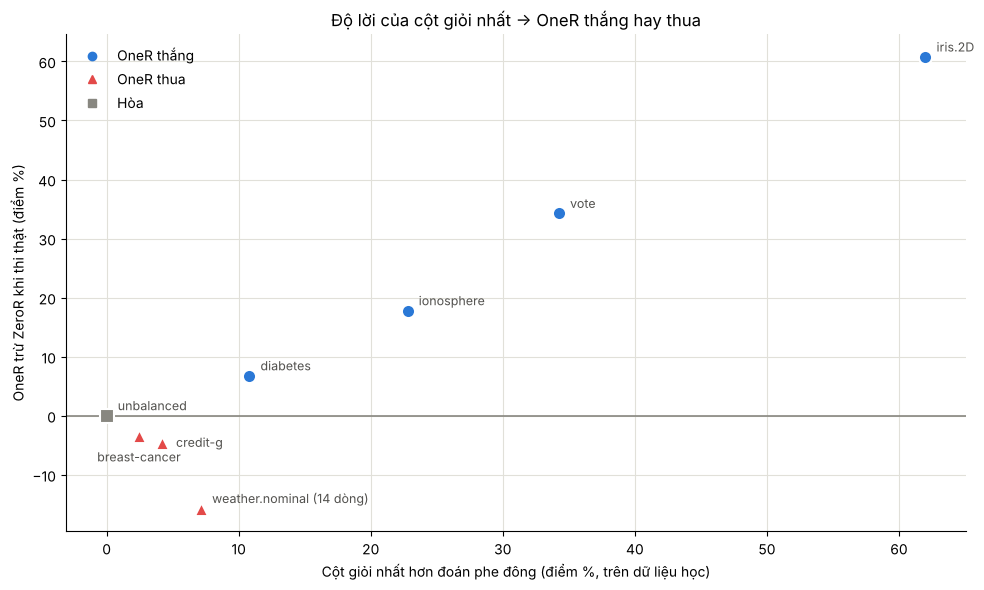

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.axhline(0, color="#888780", linewidth=1.2)

for ten, dong in ket_qua.iterrows():
    x, yv = dong["do_loi_%"], dong["OneR_tru_ZeroR_%"]
    if yv > 0.5:
        mau, hinh = XANH_DAM, "o"      # thắng: hình tròn
    elif yv < -0.5:
        mau, hinh = DO, "^"            # thua: tam giác
    else:
        mau, hinh = "#888780", "s"     # hòa: hình vuông
    ax.scatter(x, yv, s=90, color=mau, marker=hinh, edgecolors="white", linewidths=1.5, zorder=3)
    nhan = ten + (f" ({dong['so_dong']} dòng)" if dong["so_dong"] < 50 else "")
    lech, canh = {"breast-cancer": ((0, -18), "center"), "credit-g": ((10, -3), "left")}.get(ten, ((8, 4), "left"))
    ax.annotate(nhan, (x, yv), textcoords="offset points", xytext=lech, fontsize=9, color="#52514e", ha=canh)

ax.set_xlabel("Cột giỏi nhất hơn đoán phe đông (điểm %, trên dữ liệu học)")
ax.set_ylabel("OneR trừ ZeroR khi thi thật (điểm %)")
ax.set_title("Độ lời của cột giỏi nhất → OneR thắng hay thua")
ax.grid(color="#e1e0d9")
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

from matplotlib.lines import Line2D
chu_giai = [Line2D([], [], marker="o", color=XANH_DAM, linestyle="", label="OneR thắng"),
            Line2D([], [], marker="^", color=DO, linestyle="", label="OneR thua"),
            Line2D([], [], marker="s", color="#888780", linestyle="", label="Hòa")]
ax.legend(handles=chu_giai, loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## 9. Soi kỹ: cột nào "biết" nhiều nhất trong mỗi dataset?

Top 3 cột của từng dataset, kèm số khúc. Cột số bị cắt quá nhiều khúc (như `credit_amount` của credit-g) là dấu hiệu học vẹt.

In [12]:
for ten in DATASETS:
    X, y, loai_cot, thu_tu_nhan = doc_arff(ten)
    one = OneR().fit(X, y, loai_cot, thu_tu_nhan)
    phe = Counter(y).most_common(1)[0][1]
    top = sorted(one.bang_cot, key=lambda t: -t[1])[:3]
    chu = ", ".join(f"{c}: {d}/{len(y)} ({k} khúc)" for c, d, k in top)
    print(f"{ten:16s} | phe đông {phe}/{len(y)} | {chu}")

breast-cancer    | phe đông 201/286 | inv-nodes: 208/286 (7 khúc), node-caps: 207/286 (3 khúc), deg-malig: 206/286 (3 khúc)
credit-g         | phe đông 700/1000 | credit_amount: 742/1000 (26 khúc), credit_history: 717/1000 (5 khúc), duration: 711/1000 (4 khúc)
diabetes         | phe đông 500/768 | plas: 583/768 (10 khúc), mass: 550/768 (20 khúc), pedi: 547/768 (26 khúc)
ionosphere       | phe đông 225/351 | a06: 305/351 (7 khúc), a27: 302/351 (7 khúc), a08: 301/351 (5 khúc)
iris.2D          | phe đông 50/150 | petallength: 143/150 (3 khúc), petalwidth: 142/150 (3 khúc)
unbalanced       | phe đông 844/856 | WBN_GC_L_0.25: 844/856 (1 khúc), WBN_GC_H_0.25: 844/856 (1 khúc), WBN_GC_L_0.50: 844/856 (1 khúc)


vote             | phe đông 267/435 | physician-fee-freeze: 416/435 (3 khúc), adoption-of-the-budget-resolution: 380/435 (3 khúc), el-salvador-aid: 369/435 (3 khúc)
weather.nominal  | phe đông 9/14 | outlook: 10/14 (3 khúc), humidity: 10/14 (2 khúc), temperature: 9/14 (3 khúc)


## 10. Kết luận

| Nhóm | Dataset | Vì sao |
|---|---|---|
| **Hòa** | unbalanced | 98,6% là `Inactive`. Nhãn `Active` chỉ 12 dòng rải rác, không gom đủ 6 dòng một khúc → luật của OneR thành "đoán Inactive hết" = ZeroR. |
| **Thua** | breast-cancer, credit-g | Cột giỏi nhất chỉ lời 2–4 điểm. Phần lời này là trùng hợp; ra thi thật mất hết. credit-g còn bị cắt `credit_amount` thành 26 khúc = học thuộc lòng. |
| **Thua đậm** | weather.nominal | Chỉ 14 dòng, cột giỏi nhất lời đúng 1 dòng. Rút vài dòng ra làm đề là luật lật ngược. |
| **Thắng** | diabetes, ionosphere | Lời 11–23 điểm, tiền phạt học vẹt ~5 điểm không ăn hết. |
| **Thắng đậm** | vote, iris.2D | Có một cột "nói là trúng": `physician-fee-freeze` tách gần đúng hai đảng; `petallength` tách gần đúng ba loài hoa. |

**Công thức nhớ:**

> OneR khi thi ≈ ZeroR + độ lời của cột giỏi nhất − tiền phạt học vẹt

Tiền phạt học vẹt lớn khi dữ liệu ít, hoặc luật bị cắt thành quá nhiều khúc.